# 19 - La boite a outils : afficher, diagnostiquer, juger un resultat

Ce que tout projet de vision refait sans cesse, ecrit une fois et teste :

- **`vtb.viz`** : afficher des images (8/16 bits, BGR/RGB, tenseurs normalises), des grilles,
  des masques, des cartes de chaleur, des boites ; afficher des metriques (matrice de confusion,
  ROC, PR, seuil, calibration, erreurs) et des courbes d'entrainement, y compris en direct ;
- **`vtb.toolkit`** : inventaire d'un dossier, moyenne / ecart-type, poids de classes, conversions
  en lot, video -> images, patchs ; les diagnostics d'entrainement (lr_find, sur-apprendre un
  lot, resume du modele, latence) ; les statistiques pour juger un resultat (intervalle de
  confiance, McNemar, choix du seuil, calibration) ;
- **la ligne de commande** `python -m vtb.toolkit ...` : les memes outils sans ouvrir Python.

Le fil conducteur : un petit classifieur NEU-CLS (resnet18 gele + tete lineaire) entraine ici en
une minute, pour avoir de VRAIS resultats a afficher et a juger.

Prerequis : `pip install -e .[all]` ; `python tools/get_data/get_neu_cls.py`,
`python tools/get_data/get_magnetic_tile.py`, `python tools/get_data/get_neu_det.py`.
Duree sur CPU (2 coeurs) : environ 4 minutes.

**Dans le fil** : ce notebook donne les outils de toutes les etapes ; chaque partie indique les
siennes, et le tableau final ("Ou retrouver ces outils") les rappelle outil par outil.
Le fil des 13 etapes, le meme que dans le cours : `ETAPES.md`, a la racine de la toolbox.

In [1]:
# REGLAGES : tout ce qu'on change pour ses propres donnees
from pathlib import Path  # Path : represente un chemin de fichier, fonctionne sous Windows comme sous Linux

import torch  # PyTorch : tenseurs (tableaux de nombres, sur CPU ou GPU) et reseaux de neurones

NEU_DIR = Path("data/raw/neu_cls_flat")  # images NEU-CLS (defauts d'acier), rangees en dossier <classe>/<image>
TILE_DIR = Path("data/raw/magnetic_tile")  # Magnetic Tile : images .jpg + masques .png a cote
NEU_DET_DIR = Path("data/raw/neu_det")  # NEU-DET (detection) : images + annotations VOC (fichiers XML de boites)
OUT = Path("outputs/notebooks/19_boite_a_outils")  # dossier ou le notebook ecrit ses fichiers
PER_CLASS = 80  # images par classe pour le fil conducteur (QUICK)
IMAGE_SIZE = 128  # cote (pixels) des images donnees au reseau
SEED = 0  # graine du hasard : memes tirages a chaque execution
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # carte graphique (GPU, "cuda") si disponible, sinon processeur
OUT.mkdir(parents=True, exist_ok=True)  # cree le dossier de sortie (et ses parents) s'il n'existe pas

In [2]:
import subprocess  # subprocess : lancer une autre commande (ici la ligne de commande de la toolbox)
import sys  # sys : donne le chemin du Python en cours (sys.executable)
import warnings  # warnings : masquer des avertissements trop bavards

import cv2  # OpenCV : lecture, ecriture et traitement d'images (et de videos)
import matplotlib.pyplot as plt  # matplotlib : tracer des figures
import numpy as np  # numpy : calcul sur des tableaux de nombres (une image = un tableau)
import pandas as pd  # pandas : tableaux de donnees (DataFrame)
from IPython.display import display  # display : affiche joliment un tableau dans le notebook
from torch import nn  # nn : briques des reseaux (couches, fonctions de perte)

from vtb import viz  # affichage de la toolbox : images, grilles, metriques, courbes
from vtb.io.images import read_image, read_mask  # lecture robuste d'images (8/16 bits, accents) et de masques 0/1
from vtb.toolkit import dataset as ds  # outils sur les dossiers d'images (inventaire, conversions...), abrege ds
from vtb.toolkit import stats  # statistiques pour juger un resultat (intervalles, McNemar, seuils)
from vtb.toolkit import training as tt  # diagnostics et briques d'entrainement, abrege tt

warnings.filterwarnings("ignore", category=UserWarning)  # masque les avertissements d'usage
viz.setup_notebook(dpi=80, fmt="jpeg")  # figures en 80 points par pouce et en JPEG : notebook plus leger
tt.seed_everything(SEED)  # fixe toutes les graines (Python, numpy, PyTorch) : resultats reproductibles
print("device :", DEVICE)  # affiche ou tournent les calculs (cuda ou cpu)

device : cpu


## Partie A - Afficher des images avec `vtb.viz` (etapes 2, 5, 6 et 7)

### A.1 Une image, quelle qu'elle soit

`viz.show` accepte une image grise ou couleur, 8 ou 16 bits, flottante, un tenseur torch
(C, H, W), et sait annuler une normalisation (`mean`, `std`). Le titre rappelle la forme, le
type et la plage de valeurs : la moitie des bugs de vision se voient la (image vide, 16 bits
lue en 8 bits, canaux inverses, valeurs deja normalisees).

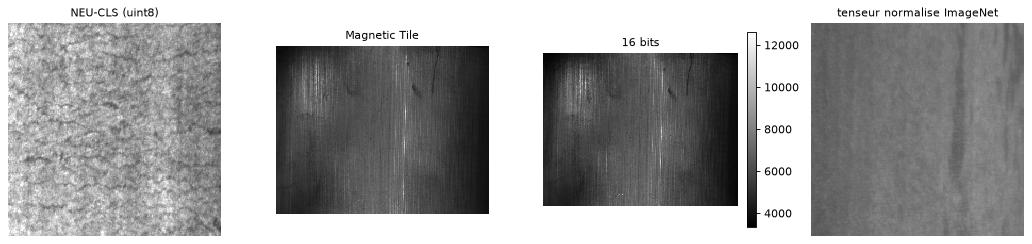

In [3]:
neu_paths = sorted(NEU_DIR.glob("*/*.bmp"))  # toutes les images NEU-CLS (un niveau de sous-dossier), triees
tile_image_path = sorted((TILE_DIR / "MT_Crack" / "Imgs").glob("*.jpg"))[3]  # 4e image de fissure de Magnetic Tile
neu = read_image(neu_paths[0], color="gray")  # une image NEU-CLS en gris (uint8 = entiers 0-255)
tile = read_image(tile_image_path, color="gray")  # la tuile en gris
sixteen = (tile.astype(np.uint16) * 40 + 3000).astype(np.uint16)  # une "camera 16 bits" simulee (valeurs de 3000 a ~13000)
normalized = (  # un tenseur normalise ImageNet, comme celui que recoit un reseau
    # HWC -> CHW (permute), valeurs dans [0, 1], puis moins la moyenne ImageNet de chaque canal
    torch.from_numpy(read_image(neu_paths[400])).permute(2, 0, 1).float() / 255 - torch.tensor([0.485, 0.456, 0.406])[:, None, None]
) / torch.tensor([0.229, 0.224, 0.225])[:, None, None]  # divise par l'ecart-type de chaque canal

fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))  # une figure avec 4 graphiques cote a cote
viz.show(neu, "NEU-CLS (uint8)", ax=axes[0])  # image 8 bits ; le titre rappelle forme, type et plage de valeurs
viz.show(tile, "Magnetic Tile", ax=axes[1])  # la tuile
viz.show(sixteen, "16 bits", ax=axes[2], colorbar=True)  # image 16 bits, avec l'echelle des valeurs (colorbar)
# tenseur normalise : mean / std permettent d'annuler la normalisation pour l'affichage
viz.show(normalized, "tenseur normalise ImageNet", ax=axes[3], mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
plt.tight_layout()  # ajuste les marges pour que rien ne se chevauche
plt.show()  # affiche la figure

### A.2 Beaucoup d'images : `viz.grid` et `viz.class_montage`

Une grille de 60 vignettes est assemblee en UNE seule image (une seule `imshow`) : instantane,
meme pour des centaines d'images, la ou une figure a 60 sous-graphes prend plusieurs secondes.
`borders` colore le cadre (vert / rouge pour juste / faux) ; `class_montage` donne le tour d'un
jeu de donnees en un coup d'oeil, n images par classe.

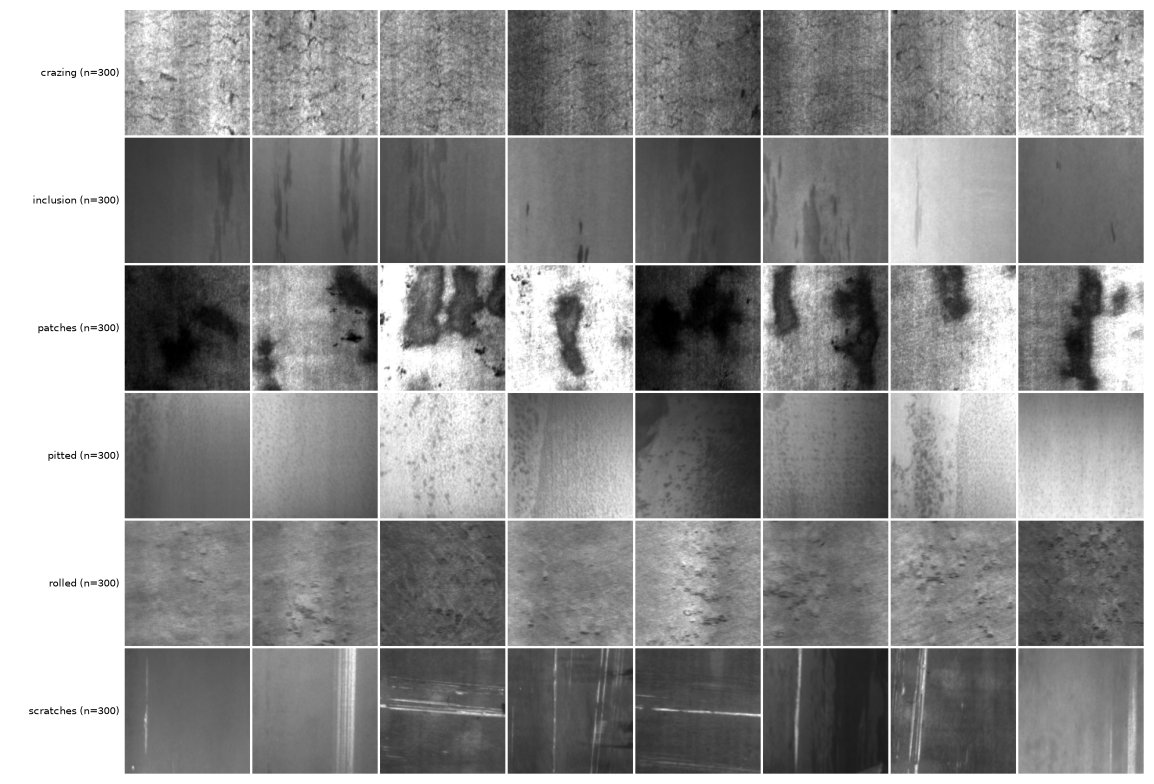

In [4]:
labels = [p.parent.name for p in neu_paths]  # classe de chaque image = nom de son dossier
viz.class_montage(neu_paths, labels, per_class=8, seed=SEED)  # 8 images tirees au hasard par classe
plt.show()  # affiche la figure

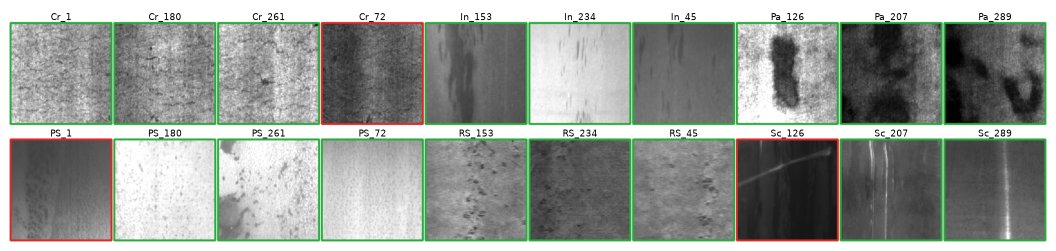

In [5]:
sample = [read_image(p, color="gray") for p in neu_paths[::90][:20]]  # 20 images, une tous les 90 fichiers ([::90])
# grille de 10 colonnes, titre = nom du fichier ; borders : cadre vert (True) ou rouge (False), ici un rouge sur 7
viz.grid(sample, [Path(p).stem for p in neu_paths[::90][:20]], ncols=10, size=1.3, borders=[i % 7 != 3 for i in range(20)])
plt.show()  # affiche la figure

### A.3 Comparer, histogramme, profil

`compare` met des versions d'une meme image cote a cote (avant / apres pretraitement).
`histogram` et `profile` disent ce que l'oeil ne voit pas : une dynamique ecrasee, une saturation,
un eclairage qui baisse d'un bord a l'autre (le profil moyen des colonnes n'est pas plat).

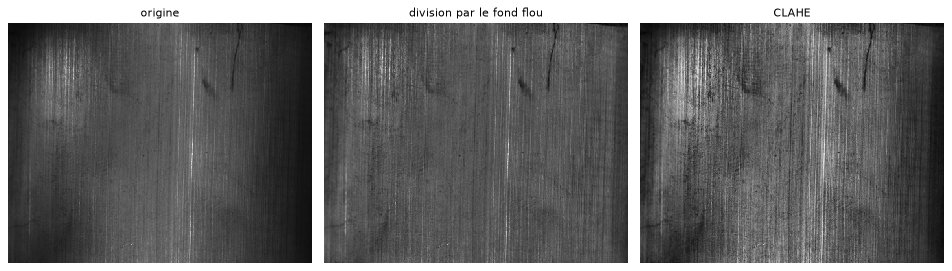

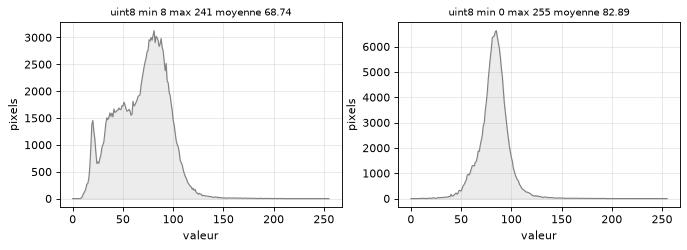

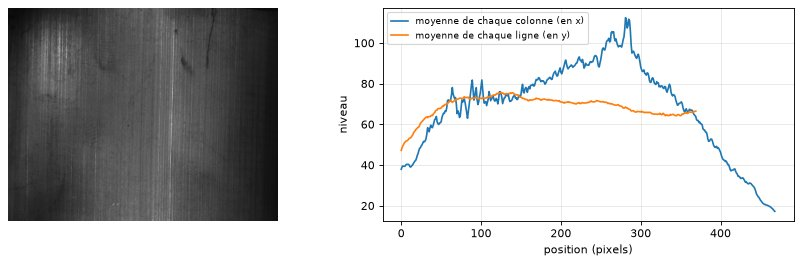

In [6]:
background = cv2.GaussianBlur(tile.astype(np.float32), (0, 0), 25)  # fond estime : flou tres fort (sigma 25) de la tuile
# tuile / fond (eclairage corrige, + 1 evite la division par zero), etiree sur 0-255 (NORM_MINMAX), en uint8
flat = cv2.normalize(tile.astype(np.float32) / (background + 1), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
# CLAHE : egalisation d'histogramme locale (par cases 8 x 8), contraste limite a 2 pour ne pas amplifier le bruit
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(tile)
viz.compare({"origine": tile, "division par le fond flou": flat, "CLAHE": clahe})  # les 3 versions cote a cote (titre: image)
plt.show()  # affiche la figure
fig, axes = plt.subplots(1, 2, figsize=(10, 3))  # 2 graphiques cote a cote
viz.histogram(tile, ax=axes[0])  # histogramme des niveaux de gris de la tuile d'origine
viz.histogram(flat, ax=axes[1])  # et de la tuile corrigee
plt.show()  # affiche la figure
viz.profile(tile)  # profils moyens des lignes et des colonnes : un eclairage inegal se voit (courbe non plate)
plt.show()  # affiche la figure

### A.4 Masques, cartes de chaleur, boites

Trois superpositions qui reviennent dans toutes les taches : un masque de segmentation (classes
en couleur, contours), une carte de chaleur (anomalie, Grad-CAM), des boites (verite en trait
vert, predictions en couleur de classe avec leur score).

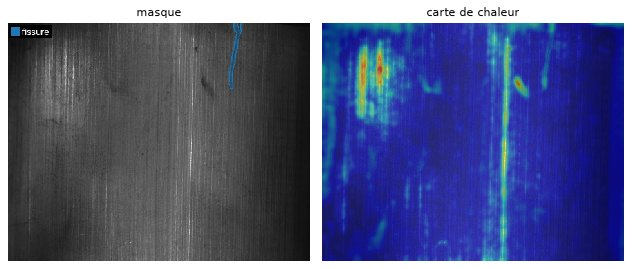

In [7]:
mask = read_mask(tile_image_path.with_suffix(".png"))  # masque de la fissure : 0 = fond, 1 = defaut
heat = cv2.GaussianBlur(np.abs(tile.astype(np.float32) - background), (0, 0), 3)  # fausse carte de chaleur : ecart au fond, lisse
overlays = {  # deux superpositions a comparer (titre : image)
    "masque": viz.overlay_mask(tile, mask, class_names=["fond", "fissure"]),  # masque colore + contours, avec legende
    "carte de chaleur": viz.overlay_heatmap(tile, heat),  # carte de chaleur fondue sur la tuile
}
viz.compare(overlays)  # cote a cote
plt.show()  # affiche la figure

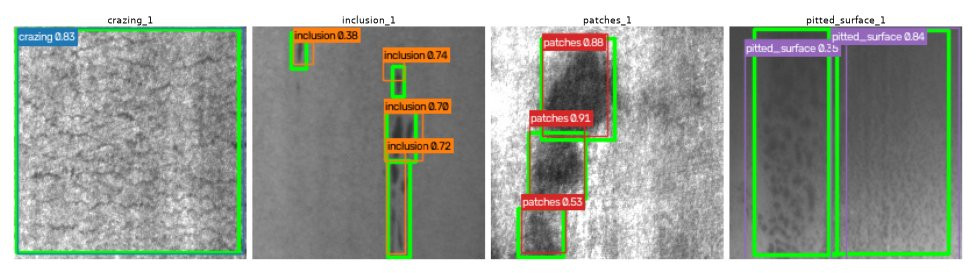

In [8]:
from vtb.annotate.formats import read_annotations  # lit des annotations (VOC, COCO, YOLO...) en objets Python
from vtb.annotate.schema import class_names_of  # liste des classes presentes dans des annotations

annotations = read_annotations("voc", NEU_DET_DIR / "IMAGES", NEU_DET_DIR / "ANNOTATIONS")  # une annotation (boites) par image
class_names = class_names_of(annotations)  # noms des classes trouvees
# pour 4 classes : la premiere image dont la classe principale est cette classe
det = [next(a for a in annotations if a.main_label() == name) for name in class_names[:4]]  # une image par classe
panels = []  # images a afficher
rng = np.random.default_rng(SEED)  # generateur aleatoire reproductible
for annotation in det:  # pour chaque image choisie
    image = read_image(annotation.image_path, color="gray")  # l'image en gris
    boxes = np.array([[b.x1, b.y1, b.x2, b.y2] for b in annotation.boxes], dtype=float)  # ses boites vraies, coins x1 y1 x2 y2
    labels_idx = [class_names.index(b.label) for b in annotation.boxes]  # numero de classe de chaque boite
    pred = {  # une "prediction" simulee : boites decalees, scores aleatoires
        "boxes": boxes + rng.normal(0, 6, boxes.shape),  # boites vraies decalees d'un bruit gaussien (ecart-type 6 px)
        "labels": labels_idx,  # memes classes
        "scores": rng.uniform(0.3, 0.95, len(boxes)),  # scores tires au hasard entre 0,3 et 0,95
    }
    # verite en trait vert, predictions en couleur de classe avec leur score
    panels.append(viz.draw_detections(image, truth={"boxes": boxes, "labels": labels_idx}, pred=pred, class_names=class_names))
viz.grid(panels, [Path(a.image_path).stem for a in det], ncols=4, size=3, max_side=400)  # 4 images ; titre = nom du fichier
plt.show()  # affiche la figure

### A.5 Un lot, des augmentations, les etapes d'un pretraitement

Avant d'entrainer, regarder ce que le RESEAU recoit : un lot apres normalisation (`show_batch`
l'annule pour l'affichage), une augmentation appliquee 8 fois a la meme image (est-ce encore la
meme classe ?), chaque etape d'un pretraitement.

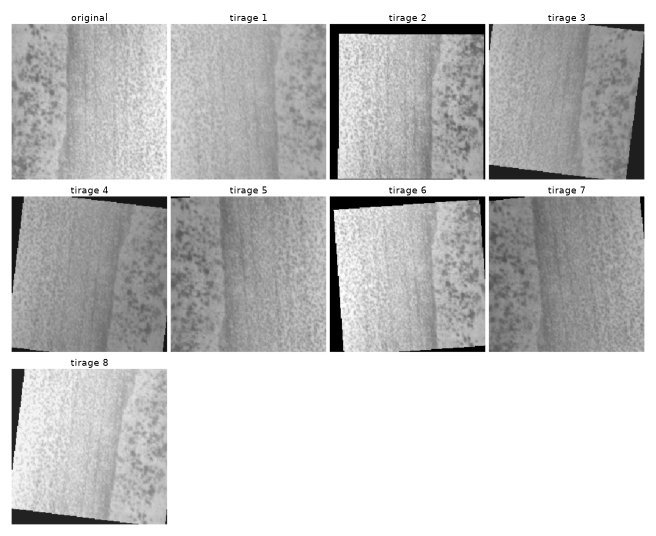

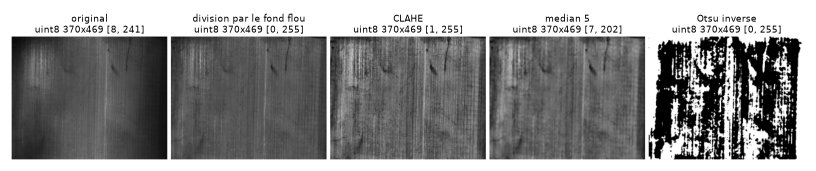

In [9]:
from torchvision.transforms import v2  # transformations d'images de torchvision (augmentations)

augment = v2.Compose(  # enchaine des augmentations aleatoires (augmentation = variante artificielle d'une image)
    [  # la liste des transformations, appliquees dans l'ordre
        v2.RandomHorizontalFlip(),  # miroir gauche-droite, une fois sur deux
        v2.RandomVerticalFlip(),  # miroir haut-bas, une fois sur deux
        v2.RandomAffine(degrees=8, translate=(0.05, 0.05), scale=(0.9, 1.1)),  # rotation +/- 8 degres, decalage 5 %, zoom 0,9-1,1
        v2.ColorJitter(brightness=0.3, contrast=0.3),  # luminosite et contraste modifies de +/- 30 %
    ]
)
viz.show_augmentations(read_image(neu_paths[1000]), augment, n=8)  # la meme image augmentee 8 fois
plt.show()  # affiche la figure


def divide_background(im: np.ndarray) -> np.ndarray:  # corrige l'eclairage ; renvoie une image 0-255 (uint8)
    """Correction d'illumination : image / fond flou, puis etirement sur 0-255."""
    flat_field = im.astype(np.float32) / (cv2.GaussianBlur(im, (0, 0), 25).astype(np.float32) + 1)  # image / fond flou (+1 : pas de / 0)
    return cv2.normalize(flat_field, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)  # etire sur 0-255, repasse en uint8


steps = [  # chaque etape s'applique a la sortie de la precedente
    ("division par le fond flou", divide_background),  # (titre, fonction a appliquer)
    ("CLAHE", lambda im: cv2.createCLAHE(2.0, (8, 8)).apply(im)),  # lambda : petite fonction sans nom ; egalisation locale
    ("median 5", lambda im: cv2.medianBlur(im, 5)),  # filtre median 5 x 5 : efface le grain
    # seuil d'Otsu (automatique) inverse : le sombre (defaut) devient blanc ; [1] = l'image seuillee
    ("Otsu inverse", lambda im: cv2.threshold(im, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)[1]),
]
viz.pipeline_steps(tile, steps)  # affiche l'image apres chaque etape
plt.show()  # affiche la figure

## Partie B - Les donnees avec `vtb.toolkit.dataset` (etapes 2 a 5)

### B.1 Inventaire, normalisation, poids de classes

Le premier reflexe devant un dossier recu : combien d'images, quelles tailles, quels types,
des fichiers illisibles ? Puis la moyenne et l'ecart-type du TRAIN (utiles pour un reseau appris
de zero) et, si les classes sont desequilibrees, des poids pour la perte.

In [10]:
files = ds.folder_summary(NEU_DIR)  # inventaire : une ligne par image (chemin, dossier, taille, type, lisible...)
display(ds.summarize(files))  # resume par dossier : nombre d'images, illisibles, tailles et types rencontres
# moyenne et ecart-type des pixels (ramenes dans [0, 1]) sur 300 images grises en 128 x 128 : servent a normaliser
mean, std = ds.mean_std(files["path"], size=IMAGE_SIZE, max_images=300, color="gray", seed=SEED)
print(f"moyenne {mean}, ecart-type {std} (gris, valeurs dans [0, 1], 300 images)")  # affiche les deux valeurs

# un desequilibre simule : 300 crazing, 30 scratches, 100 de chaque autre classe
unbalanced = pd.concat(  # recolle les morceaux en un seul tableau
    # pour chaque classe (ordre alphabetique) : ses n premieres images, n = 300, 100, 100, 100, 100, 30
    [files[files["folder"] == c].head(n) for c, n in zip(sorted(files["folder"].unique()), (300, 100, 100, 100, 100, 30))]
)
# poids de classe pour une perte ponderee (une classe rare pese plus), selon 3 formules : inverse, racine, nombre effectif
weights = pd.DataFrame({mode: ds.class_weights(unbalanced["folder"], mode=mode) for mode in ("inverse", "sqrt", "effective")})
weights.insert(0, "images", unbalanced["folder"].value_counts().sort_index())  # ajoute en tete le nombre d'images par classe
display(weights)  # affiche le tableau
# ecrit le catalogue desequilibre (chemin, label) en CSV
unbalanced.rename(columns={"folder": "label"})[["path", "label"]].to_csv(OUT / "unbalanced.csv", index=False)  # pour la ligne de commande

,folder,images,unreadable,sizes (HxW),channels,dtypes,extensions,mean_kb
0,crazing,300,0,200x200 (300),1,uint8,.bmp,40.1
1,inclusion,300,0,200x200 (300),1,uint8,.bmp,40.1
2,patches,300,0,200x200 (300),1,uint8,.bmp,40.1
3,pitted,300,0,200x200 (300),1,uint8,.bmp,40.1
4,rolled,300,0,200x200 (300),1,uint8,.bmp,40.1
5,scratches,300,0,200x200 (300),1,uint8,.bmp,40.1
6,TOTAL,1800,0,,,uint8,.bmp,40.1


moyenne [0.5069], ecart-type [0.2148] (gris, valeurs dans [0, 1], 300 images)


,images,inverse,sqrt,effective
crazing,300,0.4056,0.6711,0.4418
inclusion,100,1.2167,1.1625,1.2031
patches,100,1.2167,1.1625,1.2031
pitted,100,1.2167,1.1625,1.2031
rolled,100,1.2167,1.1625,1.2031
scratches,30,4.0556,2.1224,3.8739


### B.2 Echantillon equilibre, decoupage, rangement en dossiers

`sample_per_class` tire un sous-ensemble equilibre (pour un essai rapide) ; `export_imagefolder`
range un catalogue decoupe en `<split>/<classe>/` (le format qu'attendent torchvision, Keras ou
Ultralytics en classification), par copie ou par lien (pas de place perdue).

In [11]:
from sklearn.model_selection import train_test_split  # coupe un jeu en deux parties (stratifie si demande)

subset = ds.sample_per_class(files.rename(columns={"folder": "label"}), PER_CLASS, seed=SEED)  # au plus 80 images par classe
# 25 % pour le test, stratifie : chaque classe garde la meme proportion des deux cotes
train_val, test = train_test_split(subset, test_size=0.25, stratify=subset["label"], random_state=SEED)
train, val = train_test_split(train_val, test_size=0.2, stratify=train_val["label"], random_state=SEED)  # du reste : 20 % de validation
# recolle les trois parties, avec une colonne split (train / val / test)
subset = pd.concat([train.assign(split="train"), val.assign(split="val"), test.assign(split="test")], ignore_index=True)
subset[["path", "label", "split"]].to_csv(OUT / "split.csv", index=False)  # sauvegarde le decoupage
folder = ds.export_imagefolder(subset, OUT / "imagefolder", mode="link")  # range en <split>/<classe>/ par liens (sans copie)
display(subset.groupby(["split", "label"]).size().unstack(fill_value=0))  # nombre d'images par split (lignes) et par classe
print(folder["new_path"].iloc[0])  # exemple de nouveau chemin

label,crazing,inclusion,patches,pitted,rolled,scratches
split,,,,,,
test,20,20,20,20,20,20
train,48,48,48,48,48,48
val,12,12,12,12,12,12


outputs/notebooks/19_boite_a_outils/imagefolder/train/rolled/RS_112.bmp


### B.3 Conversions en lot : redimensionner, passer en 8 bits

Les conversions tournent en parallele (OpenCV relache le GIL) et gardent l'arborescence. Pour le
16 bits -> 8 bits, trois strategies : `scale` (division par 65535 : aucun contraste invente,
souvent tres sombre), `minmax` (etirement sur l'image, sensible a un pixel chaud), `percentile`
(etirement robuste, le choix par defaut quand l'intensite absolue n'a pas de sens).

120 images redimensionnees -> {'64x64': 120}


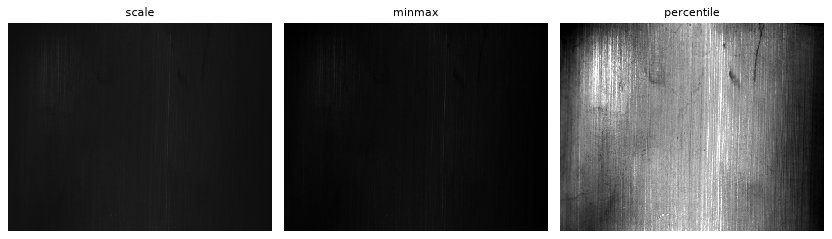

In [12]:
report = ds.resize_folder(OUT / "imagefolder" / "test", OUT / "small", 64)  # redimensionne le test en 64 x 64 dans OUT/small
print(f"{int(report['ok'].sum())} images redimensionnees ->", report["shape"].value_counts().to_dict())  # reussites et tailles
hot = sixteen.copy()  # copie de l'image 16 bits (l'originale reste intacte)
hot[0, 0] = 65535  # un seul pixel chaud
viz.compare({m: ds.to_8bit(hot, method=m) for m in ("scale", "minmax", "percentile")}, size=3.5)  # les 3 strategies 16 -> 8 bits
plt.show()  # affiche la figure

### B.4 Video -> images, grandes images -> patchs

`extract_frames` sort une image sur N (ou a une cadence donnee) d'une video de ligne ;
`patch_folder` decoupe de grandes images ET leurs masques en patchs, et peut ne garder qu'une
fraction des patchs sans defaut (`keep_empty`) quand les defauts sont rares. La colonne `source`
sert ensuite de GROUPE au decoupage : deux patchs d'une meme image restent du meme cote.

6 images extraites (2 par seconde d'une video a 20 i/s)


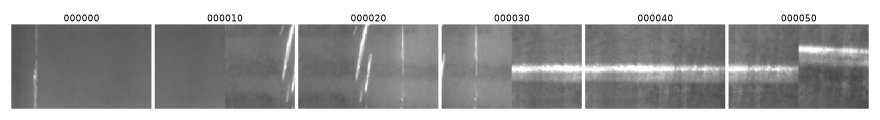

In [13]:
video_path = OUT / "ligne.avi"  # video de demonstration a fabriquer
writer = cv2.VideoWriter(str(video_path), cv2.VideoWriter_fourcc(*"MJPG"), 20.0, (200, 120))  # codec MJPG, 20 images/s, 200 x 120
# 4 images NEU de 200 px collees cote a cote (axis=1 : en largeur)
strip = np.concatenate([read_image(p, color="gray") for p in neu_paths[1500:1504]], axis=1)  # une "bande" de 800 px
for x in range(0, 600, 10):  # la camera defile le long de la bande
    writer.write(cv2.cvtColor(strip[40:160, x : x + 200], cv2.COLOR_GRAY2BGR))  # fenetre 120 x 200, en BGR (attendu par la video)
writer.release()  # ferme le fichier video
count = ds.extract_frames(video_path, OUT / "frames", fps=2)  # extrait 2 images par seconde de video ; renvoie leur nombre
frames = sorted((OUT / "frames").glob("*.png"))  # les images extraites
print(f"{count} images extraites (2 par seconde d'une video a 20 i/s)")  # affiche leur nombre
viz.grid([read_image(p) for p in frames], [p.stem[-6:] for p in frames], ncols=6, size=1.8)  # titre = 6 derniers caracteres du nom
plt.show()  # affiche la figure

342 patchs depuis 57 images ; 166 avec defaut


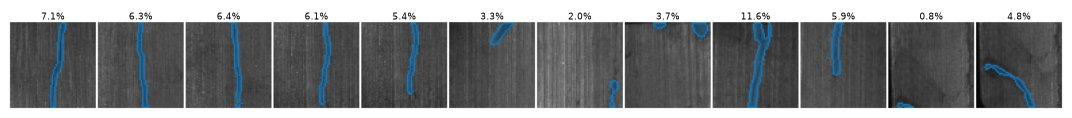

In [14]:
# decoupe les tuiles de fissure et leurs masques en patchs 64 x 64 ; garde 10 % des patchs sans defaut
patches = ds.patch_folder(TILE_DIR / "MT_Crack", OUT / "patches", size=64, keep_empty=0.1, seed=SEED)
print(f"{len(patches)} patchs depuis {patches['source'].nunique()} images ; {int(patches['has_defect'].sum())} avec defaut")  # bilan
shown = patches[patches["has_defect"]].head(12)  # 12 patchs avec defaut
viz.grid(  # les patchs avec leur masque superpose
    [viz.overlay_mask(read_image(p, color="gray"), read_mask(m)) for p, m in zip(shown["path"], shown["mask_path"])],  # patch + masque
    [f"{f:.1%}" for f in shown["defect_fraction"]],  # titre = part des pixels en defaut (pourcentage)
    ncols=12,  # 12 colonnes : une seule ligne
    size=1.1,  # petites vignettes
)
plt.show()  # affiche la figure

## Partie C - Diagnostiquer un entrainement avec `vtb.toolkit.training` (etapes 8 a 10)

### C.1 Le modele : parametres, taille, GFLOPs, latence

Avant de choisir un modele pour une ligne de production : combien de parametres (et combien
entrainables apres le gel), quelle taille sur disque, combien d'operations par image, quelle
latence REELLE sur la machine cible (`benchmark` exclut les premiers passages et donne le p95).

{'total_params': 11179590, 'trainable_params': 8396806, 'frozen_params': 2782784, 'size_mb': 42.68, 'gflops': 1.184, 'flops': 1184372736, 'input': '1x3x128x128', 'output': '1x6'}


,module,type,params,trainable,output
0,conv1,Conv2d,9408,0,1x64x64x64
1,bn1,BatchNorm2d,128,0,1x64x64x64
2,relu,ReLU,0,0,1x64x64x64
3,maxpool,MaxPool2d,0,0,1x64x32x32
4,layer1,Sequential,147968,0,1x64x32x32
5,layer2,Sequential,525568,0,1x128x16x16
6,layer3,Sequential,2099712,0,1x256x8x8
7,layer4,Sequential,8393728,8393728,1x512x4x4
8,avgpool,AdaptiveAvgPool2d,0,0,1x512x1x1
9,fc,Linear,3078,3078,1x6


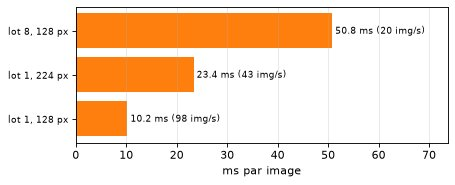

taille de lot max sur GPU : None


In [15]:
from torchvision.models import ResNet18_Weights, resnet18  # resnet18 et ses poids pre-entraines

model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)  # resnet18 pre-entraine sur ImageNet
model.fc = nn.Linear(model.fc.in_features, 6)  # nouvelle derniere couche : 512 caracteristiques -> 6 classes NEU
for name, parameter in model.named_parameters():  # pour chaque tenseur de poids du modele (avec son nom)
    parameter.requires_grad = name.startswith(("layer4", "fc"))  # gel partiel : seuls layer4 et fc restent entrainables
info, layers = tt.model_summary(model, (1, 3, IMAGE_SIZE, IMAGE_SIZE))  # parametres, taille, GFLOPs (milliards d'operations)
print(info)  # les chiffres globaux
display(layers)  # le tableau par couche
latency = {  # latence moyenne (ms) pour 3 configurations ; latence = temps de reponse
    f"lot {b}, {s} px": tt.benchmark(model, torch.randn(b, 3, s, s), warmup=2, runs=8)["mean_ms"]  # lot aleatoire, 2 chauffes, 8 mesures
    for b, s in ((1, 128), (1, 224), (8, 128))  # (taille du lot, cote de l'image en pixels)
}
viz.latency_bars(latency)  # barres des latences, avec le debit en images par seconde
plt.show()  # affiche la figure
print("taille de lot max sur GPU :", tt.max_batch_size(model, (3, IMAGE_SIZE, IMAGE_SIZE), device=DEVICE))  # None sur CPU

### C.2 Le modele PEUT-il apprendre ? `overfit_one_batch`

Le premier diagnostic quand une perte ne descend pas : un modele correct apprend par coeur UN
seul lot en quelques dizaines de pas. S'il n'y arrive pas, le probleme est dans le code (cibles,
perte, gel, taux), pas dans les donnees ; inutile de lancer 50 epoques.

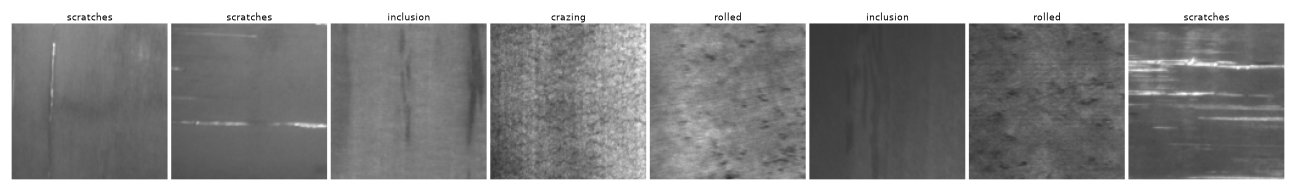

OK : perte 1.974 -> 0.0000 en 40 pas ; le modele et la perte sont capables d'apprendre.


avec lr=1e-6 : ECHEC : perte 1.966 -> 1.357 (attendu < 0.197). A verifier : cibles (indices 0..C-1, bon t ...


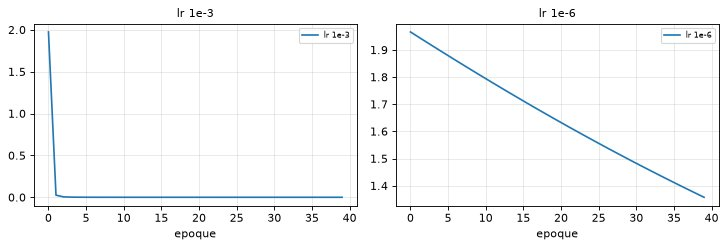

In [16]:
from torch.utils.data import DataLoader, Dataset  # Dataset : un exemple par indice ; DataLoader : les regroupe en lots

CLASSES = sorted(subset["label"].unique())  # noms des classes tries : la position d'un nom = son numero de classe
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)  # moyenne et ecart-type ImageNet par canal (normalisation)


class NeuDataset(Dataset):  # jeu de donnees PyTorch : renvoie (tenseur image, numero de classe)
    """Images NEU-CLS -> tenseur normalise ImageNet a IMAGE_SIZE ; cible = indice de classe."""

    def __init__(self, frame: pd.DataFrame) -> None:  # garde les chemins et les cibles du tableau
        self.paths, self.targets = list(frame["path"]), [CLASSES.index(c) for c in frame["label"]]  # chemins, numeros de classe

    def __len__(self) -> int:  # nombre d'exemples (le DataLoader en a besoin)
        return len(self.paths)  # une image par chemin

    def __getitem__(self, i: int):  # renvoie l'exemple numero i : (tenseur, cible)
        image = cv2.resize(read_image(self.paths[i]), (IMAGE_SIZE, IMAGE_SIZE), interpolation=cv2.INTER_AREA)  # RGB, 128 x 128
        # HWC -> CHW, valeurs dans [0, 1], puis normalisation ImageNet canal par canal
        x = (torch.from_numpy(image).permute(2, 0, 1).float() / 255 - torch.tensor(MEAN)[:, None, None]) / torch.tensor(STD)[:, None, None]
        return x, self.targets[i]  # l'image prete pour le reseau et sa classe


loaders = {  # un DataLoader par split : il fournit les images par lots (batch) de 16
    # melange (shuffle) seulement en train ; num_workers=0 : chargement dans le processus principal (plus simple)
    name: DataLoader(NeuDataset(subset[subset["split"] == name]), batch_size=16, shuffle=name == "train", num_workers=0)
    for name in ("train", "val", "test")  # pour chaque split
}
batch = next(iter(loaders["train"]))  # un premier lot : (images, cibles)
viz.show_batch(batch[0][:8], batch[1][:8], CLASSES, mean=MEAN, std=STD, ncols=8)  # 8 images du lot, normalisation annulee
plt.show()  # affiche la figure
# apprendre ce lot par coeur : 40 pas, taux 1e-3 ; CrossEntropyLoss = perte de classification (compare logits et classes)
check = tt.overfit_one_batch(model, batch, nn.CrossEntropyLoss(), steps=40, lr=1e-3, device=DEVICE)
print(check.attrs["verdict"])  # verdict : OK si la perte s'effondre
# contre-exemple : cibles melangees au hasard (randperm) et taux 1e-6, bien trop petit pour apprendre
broken = tt.overfit_one_batch(model, (batch[0], batch[1][torch.randperm(16)]), nn.CrossEntropyLoss(), steps=40, lr=1e-6, device=DEVICE)
print("avec lr=1e-6 :", broken.attrs["verdict"][:90], "...")  # debut du verdict (90 premiers caracteres)
viz.plot_history({"lr 1e-3": check["loss"].tolist(), "lr 1e-6": broken["loss"].tolist()}, save=OUT / "fig_overfit.png")  # 2 courbes
plt.show()  # affiche la figure

### C.3 Quel taux d'apprentissage ? `lr_find`

Le taux croit exponentiellement, un lot par pas ; la perte lissee descend, touche un minimum puis
explose. La suggestion est la pente la plus forte AVANT le minimum. Le modele est restaure a la
fin : c'est un diagnostic, pas un entrainement.

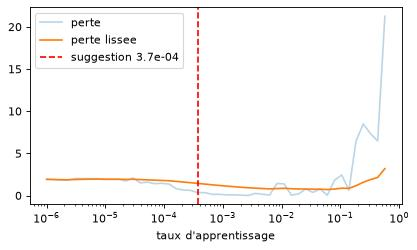

In [17]:
# taux d'apprentissage (lr) croissant de 1e-6 a 1 sur 50 lots ; renvoie la courbe et un lr suggere
curve, suggested = tt.lr_find(model, loaders["train"], nn.CrossEntropyLoss(), start_lr=1e-6, end_lr=1.0, steps=50, device=DEVICE)
fig, ax = plt.subplots(figsize=(6, 3.2))  # une figure, un graphique
ax.semilogx(curve["lr"], curve["loss"], alpha=0.3, label="perte")  # perte brute ; axe x logarithmique ; trait pale (alpha)
ax.semilogx(curve["lr"], curve["smoothed"], label="perte lissee")  # perte lissee
ax.axvline(suggested, color="red", ls="--", label=f"suggestion {suggested:.1e}")  # trait vertical rouge au lr suggere
ax.set_xlabel("taux d'apprentissage")  # nom de l'axe x
ax.legend()  # affiche la legende
fig.savefig(OUT / "fig_lr_find.png", dpi=90, bbox_inches="tight")  # sauvegarde la figure (marges ajustees)
plt.show()  # affiche la figure

### C.4 Un entrainement court avec `LivePlot`, `EarlyStopping`, `AverageMeter`, `Timer`

Pour aller vite sur CPU, le dos du reseau est gele en entier : on calcule ses caracteristiques
une fois, puis on entraine la tete lineaire. `LivePlot` redessine UNE seule figure a chaque
epoque (pas une pile de figures) ; `EarlyStopping` garde la meilleure epoque. Avec `min_delta`,
un gain plus petit que ce seuil compte comme du bruit : l'epoque retenue n'est donc pas
forcement le minimum brut de la courbe (marque sur la figure finale), et l'entrainement
s'arrete des que les progres deviennent negligeables.

caracteristiques : 2.8 s {'train': (288, 512), 'val': (72, 512), 'test': (120, 512)}


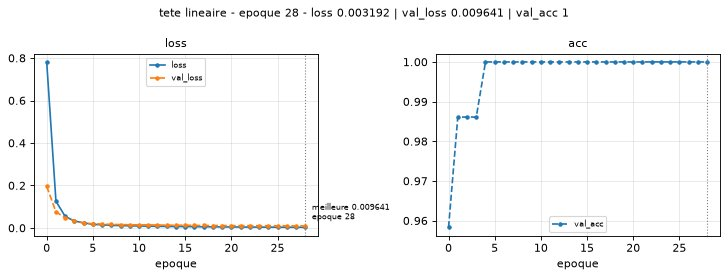

meilleure epoque : 23 (val_loss 0.010), arret a l'epoque 28


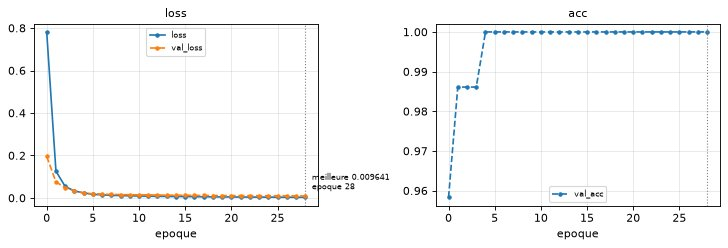

In [18]:
# le dos du reseau : toutes les couches sauf fc, puis aplatissement -> 512 nombres par image ; mode evaluation, sur DEVICE
backbone = nn.Sequential(*list(model.children())[:-1], nn.Flatten()).eval().to(DEVICE)


@torch.no_grad()  # decorateur : toute la fonction s'execute sans gradient (rien n'est appris ici)
# calcule les caracteristiques de toutes les images d'un loader ; renvoie (caracteristiques, cibles)
def features(loader: DataLoader) -> tuple[torch.Tensor, torch.Tensor]:
    xs, ys = [], []  # caracteristiques et cibles, lot par lot
    for x, y in loader:  # pour chaque lot (images, cibles)
        xs.append(backbone(x.to(DEVICE)).cpu())  # caracteristiques du lot, ramenees sur CPU
        ys.append(torch.as_tensor(y))  # cibles en tenseur
    return torch.cat(xs), torch.cat(ys)  # recolle tous les lots


with tt.Timer() as timer:  # chronometre le bloc
    # caracteristiques de chaque split, lots de 32, sans melange (meme ordre que le tableau)
    feats = {name: features(DataLoader(loader.dataset, batch_size=32)) for name, loader in loaders.items()}
print(f"caracteristiques : {timer.seconds:.1f} s", {k: tuple(v[0].shape) for k, v in feats.items()})  # duree et formes

head = nn.Linear(512, len(CLASSES))  # tete lineaire : 512 caracteristiques -> 6 logits (scores bruts par classe)
# optimiseur AdamW : met a jour les poids a partir du gradient ; lr = taille des pas ; weight_decay penalise les grands poids
optimizer = torch.optim.AdamW(head.parameters(), lr=1e-2, weight_decay=1e-2)
stopper = tt.EarlyStopping(patience=5, mode="min", min_delta=1e-3)  # un gain < 0,001 ne compte pas ; arret apres 5 epoques sans progres
live = viz.LivePlot(("loss", "val_loss", "val_acc"), title="tete lineaire")  # figure redessinee a chaque epoque
best_state = None  # poids de la meilleure epoque (aucun pour l'instant)
for epoch in range(60):  # au plus 60 epoques (une epoque = un passage sur toutes les images de train)
    head.train()  # mode entrainement
    meter = tt.AverageMeter()  # moyenne de la perte sur l'epoque
    order = torch.randperm(len(feats["train"][1]))  # ordre aleatoire des exemples de train (nouveau a chaque epoque)
    for start in range(0, len(order), 32):  # par lots de 32
        index = order[start : start + 32]  # indices du lot
        loss = nn.functional.cross_entropy(head(feats["train"][0][index]), feats["train"][1][index])  # perte : logits vs classes
        optimizer.zero_grad()  # remet les gradients a zero (sinon ils s'additionnent d'un pas a l'autre)
        loss.backward()  # calcule le gradient : comment chaque poids fait varier la perte
        optimizer.step()  # met a jour les poids dans le sens qui fait baisser la perte
        meter.update(loss.item(), len(index))  # ajoute la perte du lot, ponderee par sa taille
    head.eval()  # mode evaluation
    with torch.no_grad():  # sans gradient
        logits = head(feats["val"][0])  # logits de validation
        val_loss = nn.functional.cross_entropy(logits, feats["val"][1]).item()  # perte de validation (nombre Python)
        val_acc = (logits.argmax(1) == feats["val"][1]).float().mean().item()  # exactitude de validation
    live.update(epoch, loss=meter.avg, val_loss=val_loss, val_acc=val_acc)  # redessine la figure avec cette epoque
    if stopper.step(val_loss):  # enregistre val_loss ; vrai s'il faut s'arreter (plus de progres depuis 5 epoques)
        break  # sort de la boucle
    if stopper.improved:  # cette epoque est la meilleure jusqu'ici
        best_state = {k: v.clone() for k, v in head.state_dict().items()}  # copie independante des poids (clone)
live.close()  # fige la figure finale
head.load_state_dict(best_state)  # remet les poids de la meilleure epoque
print(f"meilleure epoque : {stopper.best_epoch} (val_loss {stopper.best:.3f}), arret a l'epoque {stopper.epoch}")  # bilan
live.history.to_csv(OUT / "history.csv", index=False)  # sauvegarde l'historique des courbes
viz.plot_history(OUT / "history.csv", best="val_loss:min", save=OUT / "fig_history.png")  # trace l'historique ; marque le min de val_loss
plt.show()  # affiche la figure

## Partie D - Afficher des metriques avec `vtb.viz` (etape 11)

Le test est lu une seule fois. Matrice de confusion (nombres ET pourcentages), rapport par classe,
courbes ROC et PR (une contre toutes), calibration (le modele est-il trop sur de lui ?) et la
galerie des erreurs les plus sures d'elles (souvent des erreurs d'etiquette).

,precision,recall,f1,support
crazing,0.9048,0.95,0.9268,20
inclusion,0.9048,0.95,0.9268,20
patches,1.0000,1.00,1.0000,20
pitted,0.9000,0.90,0.9000,20
rolled,1.0000,1.00,1.0000,20
scratches,1.0000,0.90,0.9474,20
accuracy,NaN,NaN,0.9500,120
macro avg,0.9516,0.95,0.9502,120
weighted avg,0.9516,0.95,0.9502,120


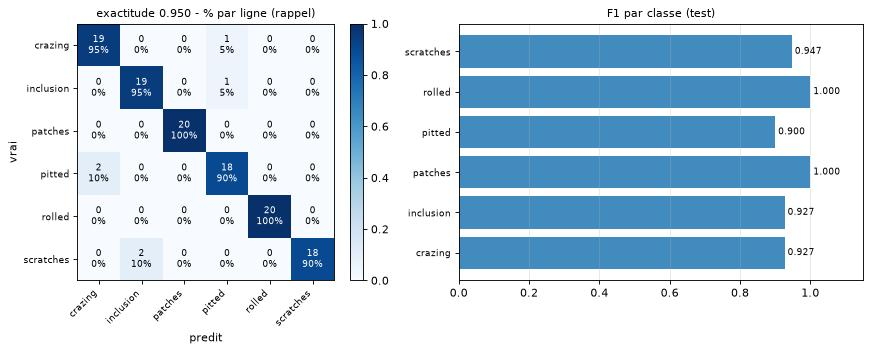

In [19]:
with torch.no_grad():  # sans gradient
    test_probs = torch.softmax(head(feats["test"][0]), 1).numpy()  # softmax : logits -> probabilites (somme 1 par image)
    val_probs = torch.softmax(head(feats["val"][0]), 1).numpy()  # probabilites de validation
y_test, y_val = feats["test"][1].numpy(), feats["val"][1].numpy()  # vraies classes, en numpy
pred_test = test_probs.argmax(1)  # classe predite = la plus probable
report_table = viz.classification_report(y_test, pred_test, CLASSES)  # precision, rappel, F1 par classe
display(report_table)  # affiche le tableau
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))  # 2 graphiques cote a cote
viz.confusion_matrix(y_test, pred_test, CLASSES, ax=axes[0])  # matrice de confusion : vraie classe x classe predite
viz.per_class_bars(report_table.loc[CLASSES, "f1"], title="F1 par classe (test)", ax=axes[1])  # F1 = equilibre precision / rappel
plt.tight_layout()  # ajuste les marges
fig.savefig(OUT / "fig_confusion.png", dpi=90, bbox_inches="tight")  # sauvegarde la figure
plt.show()  # affiche la figure

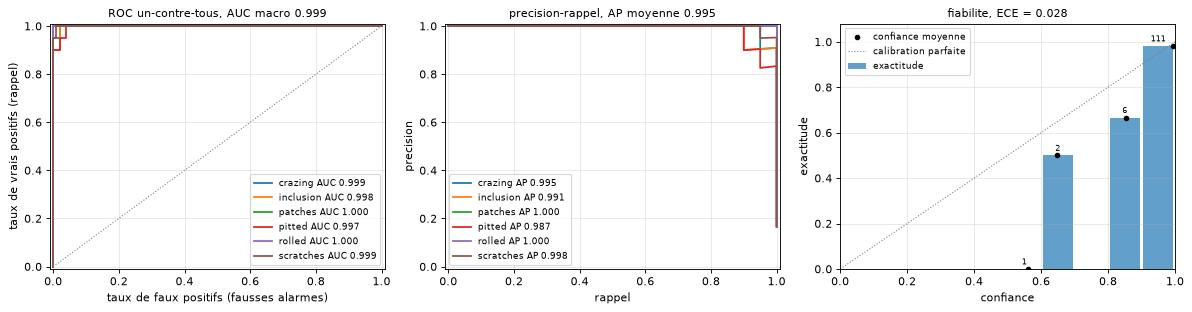

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))  # 3 graphiques cote a cote
viz.roc_curves(y_test, test_probs, CLASSES, ax=axes[0])  # ROC : vrais positifs vs faux positifs selon le seuil, par classe
viz.pr_curves(y_test, test_probs, CLASSES, ax=axes[1])  # PR : precision vs rappel selon le seuil, par classe
viz.calibration(y_test, test_probs, ax=axes[2])  # calibration : confiance annoncee vs justesse reelle
plt.tight_layout()  # ajuste les marges
fig.savefig(OUT / "fig_curves.png", dpi=90, bbox_inches="tight")  # sauvegarde la figure
plt.show()  # affiche la figure

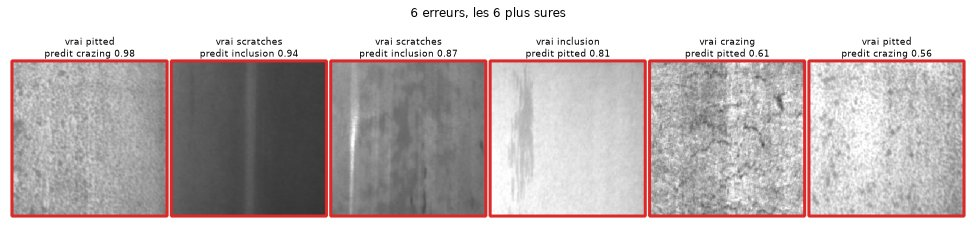

In [21]:
test_frame = subset[subset["split"] == "test"].reset_index(drop=True)  # tableau du test renumerote 0, 1, 2... (ordre de feats)
test_images = [read_image(p, color="gray") for p in test_frame["path"]]  # images de test en gris
viz.errors_gallery(test_images, y_test, pred_test, test_probs, CLASSES, k=8, save=OUT / "fig_errors.png")  # 8 pires erreurs
plt.show()  # affiche la figure

### D.2 Un seuil de decision : `threshold_sweep` et `score_histogram`

En production, la question est souvent binaire : "defaut grave ou non ?". Ici : `pitted` (la
classe la plus confondue de NEU-CLS, avec `inclusion`) contre le reste, sa probabilite comme score.
Le balayage montre rappel, precision et fausses alarmes pour chaque seuil ; l'histogramme montre
si les deux populations se separent. Le seuil se choisit sur la VALIDATION.

AUC pitted contre le reste : validation 1.000, test 0.997


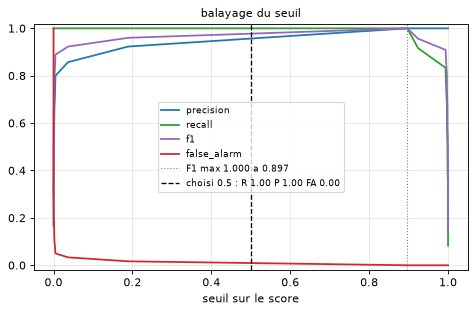

,threshold,precision,recall,f1,false_alarm,tp,fp,fn,tn
0,3.978031e-15,0.166667,1.0,0.285714,1.000000,12,60,0,0
1,1.631367e-11,0.169014,1.0,0.289157,0.983333,12,59,0,1
2,3.504024e-11,0.171429,1.0,0.292683,0.966667,12,58,0,2
3,4.888783e-10,0.173913,1.0,0.296296,0.950000,12,57,0,3
4,6.369902e-10,0.176471,1.0,0.300000,0.933333,12,56,0,4


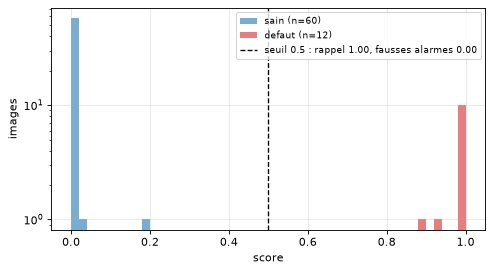

In [22]:
from sklearn.metrics import roc_auc_score  # AUC : aire sous la courbe ROC (1 = separation parfaite, 0,5 = hasard)

target = CLASSES.index("pitted")  # numero de la classe pitted
print(  # AUC de pitted contre le reste, en validation et en test
    f"AUC {CLASSES[target]} contre le reste : validation {roc_auc_score(y_val == target, val_probs[:, target]):.3f}, test {roc_auc_score(y_test == target, test_probs[:, target]):.3f}"
)
val_scores, val_defect = val_probs[:, target], y_val == target  # score = probabilite de pitted ; verite : pitted ou non
fig, sweep = viz.threshold_sweep(val_defect, val_scores, chosen=0.5, save=OUT / "fig_threshold.png")  # metriques par seuil
plt.show()  # affiche la figure
display(sweep.head())  # premieres lignes du balayage
viz.score_histogram(val_scores, val_defect, threshold=0.5, log=True)  # scores des deux populations, seuil 0,5, echelle log
plt.show()  # affiche la figure

## Partie E - Juger un resultat avec `vtb.toolkit.stats` (etape 11)

### E.1 Un chiffre sans intervalle ne veut rien dire

Sur un test de quelques centaines d'images, l'exactitude n'est connue qu'a quelques points pres.
`bootstrap_ci` reechantillonne le test (par groupe si plusieurs images viennent de la meme
piece) ; `wilson_ci` donne directement l'intervalle d'une proportion (un rappel 48/79).

In [23]:
import functools  # functools.partial : cree une fonction avec certains arguments deja fixes

from sklearn.metrics import accuracy_score, f1_score  # exactitude et F1

# exactitude et son intervalle de confiance par bootstrap (1000 tirages du test avec remise)
accuracy = stats.bootstrap_ci(accuracy_score, y_test, pred_test, n=1000, seed=SEED)
# idem pour le F1 macro (moyenne des F1 de chaque classe)
macro_f1 = stats.bootstrap_ci(functools.partial(f1_score, average="macro"), y_test, pred_test, n=1000, seed=SEED)
print(f"exactitude {accuracy}   F1 macro {macro_f1}   ({len(y_test)} images de test)")  # valeur [borne basse, borne haute]
recall_rows = []  # une ligne par classe
for k, name in enumerate(CLASSES):  # pour chaque classe (numero, nom)
    hits, total = int(((pred_test == k) & (y_test == k)).sum()), int((y_test == k).sum())  # bien reconnues / images de la classe
    interval = stats.wilson_ci(hits, total)  # rappel et son intervalle de Wilson (exact pour une proportion)
    # une ligne : classe, rappel en fraction, valeur, bornes basse et haute de l'intervalle
    recall_rows.append({"classe": name, "rappel": f"{hits}/{total}", "valeur": interval.value, "bas": interval.low, "haut": interval.high})
display(pd.DataFrame(recall_rows).round(3))  # affiche le tableau arrondi

exactitude 0.950 [0.908, 0.983]   F1 macro 0.950 [0.908, 0.984]   (120 images de test)


,classe,rappel,valeur,bas,haut
0,crazing,19/20,0.95,0.764,0.991
1,inclusion,19/20,0.95,0.764,0.991
2,patches,20/20,1.00,0.839,1.000
3,pitted,18/20,0.90,0.699,0.972
4,rolled,20/20,1.00,0.839,1.000
5,scratches,18/20,0.90,0.699,0.972


### E.2 Deux modeles : la difference est-elle reelle ? `mcnemar`

Un second modele sur les memes caracteristiques : les 5 plus proches voisins. McNemar ne regarde
que les images ou les deux modeles sont en desaccord ; p > 0,05 : ce test ne permet pas de dire
lequel est meilleur, quel que soit l'ecart d'exactitude affiche.

difference significative (p = 0.0391 < 0.05) : A est meilleur


,tete lineaire (A) / kNN (B)
n,120
accuracy_a,0.95
accuracy_b,0.8917
a_right_b_wrong,8
a_wrong_b_right,1
statistic,1.0
p_value,0.039062
method,binomial exact
verdict,difference significative (p = 0.0391 < 0.05) :...


,accuracy,f1_macro
tete lineaire,0.950,0.950
kNN k=5,0.892,0.892


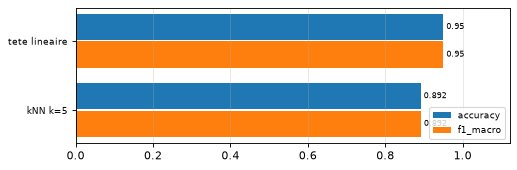

In [24]:
from sklearn.neighbors import KNeighborsClassifier  # kNN : classe d'apres les k exemples d'entrainement les plus proches

knn = KNeighborsClassifier(n_neighbors=5).fit(feats["train"][0].numpy(), feats["train"][1].numpy())  # 5 voisins, memes caracteristiques
pred_knn = knn.predict(feats["test"][0].numpy())  # ses predictions sur le test
comparison = stats.mcnemar(y_test, pred_test, pred_knn)  # McNemar : la difference entre les deux modeles est-elle reelle ?
print(comparison["verdict"])  # conclusion en une phrase
display(pd.Series(comparison).to_frame("tete lineaire (A) / kNN (B)"))  # tous les chiffres du test, en tableau
runs = {  # metriques de chaque modele
    "tete lineaire": {"accuracy": accuracy_score(y_test, pred_test), "f1_macro": f1_score(y_test, pred_test, average="macro")},  # A
    "kNN k=5": {"accuracy": accuracy_score(y_test, pred_knn), "f1_macro": f1_score(y_test, pred_knn, average="macro")},  # B
}
display(viz.metrics_table(runs))  # tableau comparatif
viz.compare_runs(runs, ["accuracy", "f1_macro"])  # barres cote a cote
plt.show()  # affiche la figure

### E.3 Le seuil pour une contrainte metier : `threshold_for`

"Au moins 95 % de ces defauts detectes" ou "au plus 2 % de fausses alarmes" : la contrainte
donne le seuil, sur la validation. Si elle est impossible sur ces donnees, la fonction le dit et
renvoie le seuil le plus proche. Puis on verifie sur le test, une fois.

Piege : avec 12 defauts en validation, "rappel >= 0,95" veut dire "les 12" ; quand la validation
est parfaitement separee, toutes les contraintes donnent le meme seuil, colle au defaut le moins
bien note, et le rappel du test est souvent plus bas. Plus la validation est petite, plus il faut
de marge (seuil un peu plus bas) et un intervalle sur le rappel du test. Avec un modele moins bon
(les 5 plus proches voisins de E.2), la contrainte stricte devient impossible et la fonction le dit.

In [25]:
for constraint in ({"min_recall": 0.95}, {"max_false_alarm": 0.02}, {"min_recall": 1.0, "max_false_alarm": 0.0}):  # 3 contraintes
    choice = stats.threshold_for(val_scores, val_defect, **constraint)  # seuil choisi sur la validation ; ** : dict -> arguments
    test_decision = test_probs[:, target] >= choice["threshold"]  # decision sur le test avec ce seuil
    # rappel du test (pitted detectes / pitted), avec son intervalle de Wilson
    test_recall = stats.wilson_ci(int((test_decision & (y_test == target)).sum()), int((y_test == target).sum()))
    test_alarm = (test_decision & (y_test != target)).sum() / (y_test != target).sum()  # fausses alarmes : autres classes signalees
    print(f"{constraint}\n   validation : {choice['message']}\n   test : rappel {test_recall}, fausses alarmes {test_alarm:.3f}")  # bilan

knn_val_scores = knn.predict_proba(feats["val"][0].numpy())[:, target]  # part des 5 voisins de la classe cible
strict = stats.threshold_for(knn_val_scores, val_defect, min_recall=1.0, max_false_alarm=0.0)  # contrainte stricte, avec le kNN
print("kNN, rappel 1 et aucune fausse alarme :", strict["message"])  # le message dit si c'est impossible

{'min_recall': 0.95}
   validation : contraintes respectees (rappel >= 0.95) au seuil 0.8968 : rappel 1.0, fausses alarmes 0.0, precision 1.0
   test : rappel 0.800 [0.584, 0.919], fausses alarmes 0.000
{'max_false_alarm': 0.02}
   validation : contraintes respectees (fausses alarmes <= 0.02) au seuil 0.8968 : rappel 1.0, fausses alarmes 0.0, precision 1.0
   test : rappel 0.800 [0.584, 0.919], fausses alarmes 0.000
{'min_recall': 1.0, 'max_false_alarm': 0.0}
   validation : contraintes respectees (rappel >= 1.0, fausses alarmes <= 0.0) au seuil 0.8968 : rappel 1.0, fausses alarmes 0.0, precision 1.0
   test : rappel 0.800 [0.584, 0.919], fausses alarmes 0.000
kNN, rappel 1 et aucune fausse alarme : IMPOSSIBLE sur ces donnees (rappel >= 1.0, fausses alarmes <= 0.0) ; le plus proche : seuil 0.4 -> rappel 1.0, fausses alarmes 0.0167, precision 0.9231


### E.4 Calibration et pires erreurs

L'ECE mesure l'ecart entre la confiance annoncee et la justesse reelle ; `worst_errors` donne
les indices des erreurs les plus sures d'elles, a ouvrir une par une.

In [26]:
ece = stats.expected_calibration_error(y_test, test_probs)  # ECE : ecart moyen entre confiance annoncee et justesse reelle
worst = stats.worst_errors(y_test, test_probs, k=5)  # indices des 5 erreurs les plus sures d'elles
print(f"ECE = {ece:.3f}")  # 0 = parfaitement calibre
display(  # tableau des pires erreurs
    test_frame.loc[worst, ["path", "label"]].assign(  # chemin et vraie classe, plus deux colonnes ajoutees
        predit=[CLASSES[i] for i in pred_test[worst]],  # classe predite
        confiance=test_probs[worst].max(1).round(3),  # probabilite donnee a la classe predite
    )
)

ECE = 0.034


,path,label,predit,confiance
42,data/raw/neu_cls_flat/pitted/PS_105.bmp,pitted,crazing,0.979
112,data/raw/neu_cls_flat/scratches/Sc_44.bmp,scratches,inclusion,0.936
52,data/raw/neu_cls_flat/scratches/Sc_95.bmp,scratches,inclusion,0.871
106,data/raw/neu_cls_flat/inclusion/In_297.bmp,inclusion,pitted,0.812
9,data/raw/neu_cls_flat/crazing/Cr_258.bmp,crazing,pitted,0.615


## Partie F - Les memes outils en ligne de commande (toutes les etapes)

`python -m vtb.toolkit <commande> --help` pour chaque commande. Les CSV ecrits ici (scores de
validation, predictions du test) sont ceux que produisent aussi les scripts `predict` des recettes.

In [27]:
# scores de validation et verite (0 / 1) en CSV, pour la commande "threshold"
pd.DataFrame({"score": val_scores, "is_defect": val_defect.astype(int)}).to_csv(OUT / "val_scores.csv", index=False)
# predictions de test des deux modeles (noms de classe) en CSV, pour les commandes "ci" et "mcnemar"
test_frame.assign(pred=[CLASSES[i] for i in pred_test], knn=[CLASSES[i] for i in pred_knn]).to_csv(
    OUT / "test_predictions.csv",  # fichier de sortie
    index=False,  # sans la colonne d'index
)
commands = [  # commandes de la boite a outils a lancer (chaque commande = liste de mots)
    ["summary", str(TILE_DIR / "MT_Crack"), "--ext", ".jpg"],  # inventaire du dossier des fissures
    ["mean-std", str(NEU_DIR), "--gray", "--max-images", "200", "--size", "128"],  # moyenne / ecart-type en gris
    ["class-weights", "--csv", str(OUT / "unbalanced.csv"), "--mode", "sqrt"],  # poids de classes du catalogue desequilibre
    ["threshold", str(OUT / "val_scores.csv"), "--min-recall", "0.95"],  # seuil pour un rappel d'au moins 95 %
    ["ci", str(OUT / "test_predictions.csv"), "--true", "label", "--pred", "pred", "--n", "500"],  # intervalle par bootstrap
    ["mcnemar", str(OUT / "test_predictions.csv"), "--true", "label", "--pred-a", "pred", "--pred-b", "knn"],  # McNemar A / B
]
for command in commands:  # pour chaque commande
    print("$ python -m vtb.toolkit", " ".join(command))  # affiche la commande telle qu'on la taperait
    # la lance avec le meme Python ; capture_output + text : sortie recuperee en texte ; check=True : erreur si elle echoue
    result = subprocess.run([sys.executable, "-m", "vtb.toolkit", *command], capture_output=True, text=True, check=True)
    print(result.stdout)  # affiche ce qu'elle a ecrit

$ python -m vtb.toolkit summary data/raw/magnetic_tile/MT_Crack --ext .jpg


| folder   |   images |   unreadable | sizes (HxW)                                       |   channels | dtypes   | extensions   |   mean_kb |
|----------|----------|--------------|---------------------------------------------------|------------|----------|--------------|-----------|
| Imgs     |       57 |            0 | 260x596 (3), 244x599 (3), 242x594 (3), +46 autres |          1 | uint8    | .jpg         |      42.7 |
| TOTAL    |       57 |            0 |                                                   |            | uint8    | .jpg         |      42.7 |

$ python -m vtb.toolkit mean-std data/raw/neu_cls_flat --gray --max-images 200 --size 128


images : 200 sur 1800
mean: [0.5052]
std:  [0.2073]

$ python -m vtb.toolkit class-weights --csv outputs/notebooks/19_boite_a_outils/unbalanced.csv --mode sqrt


| classe    |   images |   poids |
|-----------|----------|---------|
| crazing   |      300 |  0.6711 |
| inclusion |      100 |  1.163  |
| patches   |      100 |  1.163  |
| pitted    |      100 |  1.163  |
| rolled    |      100 |  1.163  |
| scratches |       30 |  2.122  |

liste pour la perte : [0.6711, 1.1625, 1.1625, 1.1625, 1.1625, 2.1224]

$ python -m vtb.toolkit threshold outputs/notebooks/19_boite_a_outils/val_scores.csv --min-recall 0.95


|                  | valeur                                                                                                   |
|------------------|----------------------------------------------------------------------------------------------------------|
| threshold        | 0.8967978                                                                                                |
| recall           | 1.0                                                                                                      |
| false_alarm_rate | 0.0                                                                                                      |
| precision        | 1.0                                                                                                      |
| feasible         | True                                                                                                     |
| message          | contraintes respectees (rappel >= 0.95) au seuil 0.8968 : rappel 1.0, fausses alarm

120 exemples, 500 tirages bootstrap
| metrique   |   valeur |   bas (95 %) |   haut (95 %) |
|------------|----------|--------------|---------------|
| accuracy   |   0.95   |       0.9083 |        0.9833 |
| f1_macro   |   0.9502 |       0.9087 |        0.9841 |

$ python -m vtb.toolkit mcnemar outputs/notebooks/19_boite_a_outils/test_predictions.csv --true label --pred-a pred --pred-b knn


|                 | valeur                                                        |
|-----------------|---------------------------------------------------------------|
| n               | 120                                                           |
| accuracy_a      | 0.95                                                          |
| accuracy_b      | 0.8917                                                        |
| a_right_b_wrong | 8                                                             |
| a_wrong_b_right | 1                                                             |
| statistic       | 1.0                                                           |
| p_value         | 0.0390625                                                     |
| method          | binomial exact                                                |
| verdict         | difference significative (p = 0.0391 < 0.05) : A est meilleur |



## Ou retrouver ces outils

| etape(s) | besoin | outil |
|---|---|---|
| 2, 5 | voir une image, une grille, un avant / apres, un histogramme, un profil | `viz.show`, `viz.grid`, `viz.compare`, `viz.histogram`, `viz.profile` |
| 2, 11 | superposer masque, carte, boites | `viz.overlay_mask`, `viz.overlay_heatmap`, `viz.draw_boxes`, `viz.draw_detections` |
| 5, 6, 7 | voir ce que recoit le reseau | `viz.show_batch`, `viz.show_augmentations`, `viz.pipeline_steps` |
| 11 | metriques | `viz.confusion_matrix`, `viz.classification_report`, `viz.roc_curves`, `viz.pr_curves`, `viz.threshold_sweep`, `viz.score_histogram`, `viz.calibration`, `viz.errors_gallery`, `viz.metrics_table`, `viz.compare_runs` |
| 10 | courbes d'entrainement | `viz.plot_history`, `viz.LivePlot` |
| 2, 5, 7 | inventaire, normalisation, poids | `ds.folder_summary`, `ds.summarize`, `ds.mean_std`, `ds.class_weights`, `ds.sample_weights` |
| 2, 5 | conversions en lot | `ds.resize_folder`, `ds.convert_folder_8bit`, `ds.export_imagefolder`, `ds.extract_frames`, `ds.patch_folder` |
| 8, 9, 10 | diagnostics | `tt.overfit_one_batch`, `tt.lr_find`, `tt.model_summary`, `tt.benchmark`, `tt.max_batch_size` |
| 1, 10 | boucle | `tt.EarlyStopping`, `tt.AverageMeter`, `tt.Timer`, `tt.seed_everything` |
| 11 | juger | `stats.bootstrap_ci`, `stats.wilson_ci`, `stats.mcnemar`, `stats.threshold_for`, `stats.expected_calibration_error`, `stats.worst_errors` |

Pour aller plus loin : l'article `docs/outils.md` (reference) et `docs/guide_autonomie.md`
(entrainer de A a Z, et quoi faire quand ca ne marche pas).